# 03-1. 관측값 추정: 후보 모델과 교차검증

도로기상 미관측 지점의 관측값을 추정하는 모델을 학습하고 검증 지점에서 평가한다(03).
이 노트북은 1~2장으로, 학습/검증 지점을 나누고 후보 방법을 지점 단위 교차검증으로 비교해 최종 방법을 고른다.

03 구성: **03-1 후보 모델·교차검증(1~2장)** · 03-2 추가 실험(3장) · 03-3 검증 지점 평가·시각화·저장(4~6장)

- 검증 지점(학습 제외): 부곡교 12410, 삼봉 33411, 해전 23402
- 평가 지표: BIAS, MAE, RMSE

검증 지점은 모두 목표(결빙) 관측소라서 노면상태와 **노면온도**만 관측한다(01-2의 3-2 참고). 따라서 추정 대상은 노면온도이다.
노면온도는 결빙 판단의 핵심 변수이고, 04의 결빙 분류와 05의 구간별 위험도에 입력으로 쓰인다.

- 입력: 02-2의 지점 변수 (`data/processed/station_features.parquet`)
- 출력: 교차검증 예측·설정 (`data/processed/estimation_oof.parquet`, `estimation_cv.json`, 03-2·03-3에서 사용), 교차검증 성능 (`data/results/estimation_cv_scores.csv`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

for d in [config.RESULT_DIR, config.MODEL_DIR, config.FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "rst"  # 노면온도

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
meta = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))
FEATURES = meta["features"]
print(sf.shape, f"변수 {len(FEATURES)}개")
for group, cols in meta["groups"].items():
    print(f"  {group}: {', '.join(cols)}")

(587520, 47) 변수 40개
  기상: ta, td, rh, dpd, ws, rain, pr60, pr12h, pr_day, cloud, tg, snow, sunshine, ta_d1h, ta_d3h, ta_min12h, rh_mean3h, rain_hrs12h, hrs_since_rain
  주변도로기상: nbr_rst, nbr_anom, rst_phys, nbr_ice, nbr_ice_3h, nbr_wet, nbr_snow, nbr_dist
  시간·일사: hour_sin, hour_cos, sun_elev, season_day, sunlit, solar_eff
  지형: elev, tpi, relief, shade_winter, dist_river
  도로: dist_bridge, dist_tunnel


## 1. 학습/검증 데이터 분리

검증 지점 3곳은 학습에서 완전히 뺀다. 02-2에서 만든 주변 RWIS 변수도 학습 지점 14곳만 원천으로 썼으므로
검증 지점의 관측값은 어떤 형태로도 학습에 들어가지 않는다.

In [4]:
def split_holdout(df):
    """검증 지점(config.HOLDOUT_STATIONS)을 학습 데이터에서 분리한다."""
    is_holdout = df["stn"].isin(config.HOLDOUT_STATIONS)
    return df[~is_holdout].reset_index(drop=True), df[is_holdout].reset_index(drop=True)


train_all, holdout = split_holdout(sf)
train = train_all.dropna(subset=[TARGET])
print(f"학습 지점 {train_all['stn'].nunique()}곳: {train.shape[0]:,}행 (노면온도 결측 제외)")
print(f"검증 지점 {holdout['stn'].nunique()}곳: {holdout[TARGET].notna().sum():,}행")
pd.DataFrame({stn: {"지점명": name, "노선": route} for stn, (name, route) in config.HOLDOUT_STATIONS.items()}).T

학습 지점 14곳: 479,843행 (노면온도 결측 제외)
검증 지점 3곳: 103,677행


,지점명,노선
12410,부곡교,서해안
33411,삼봉,통영-대전중부선
23402,해전,호남선


## 2. 모델 구성 및 학습

### 검증 방식

학습 지점 14곳을 2곳씩 7묶음으로 나눈 **지점 단위 교차검증**을 한다. 한 묶음의 지점은 학습에 쓰지 않은 채 예측하므로
미관측 지점 추정과 같은 조건이다. 성능은 지점별 RMSE의 평균으로 비교하고,
**최종 방법은 교차검증 성능으로만 고른다** (검증 지점 3곳은 마지막 평가에만 쓴다).

### 후보

| 이름 | 방법 | 입력 |
|------|------|------|
| B0 보간 기온 | 노면온도 = 보간 기온, 학습 없음 (노면 에너지 수지를 무시한 가장 단순한 근사, 비교 기준) | `ta` |
| B1 주변 노면온도 | 가까운 RWIS 3곳 노면온도 IDW (고도 보정), 학습 없음 | `nbr_rst` |
| B2 기온+노면편차 | 보간 기온 + 주변 RWIS (노면온도-기온) 편차 IDW, 학습 없음 | `rst_phys` |
| LightGBM(전체) | 그래디언트 부스팅 | 02-2의 변수 전체 |
| LightGBM(핵심) | 그래디언트 부스팅, 작은 트리 | 핵심 변수 |
| Ridge(핵심) | 선형 회귀 (L2 규제) | 핵심 변수 |
| 앙상블 | LightGBM(핵심), Ridge(핵심), B1의 단순 평균 | |

핵심 변수는 지점이 바뀌어도 관계가 유지될 만한 것으로 골랐다: 주변 RWIS 노면온도, 보간 기온·지면온도·이슬점·습도·풍속·운량·일조,
태양고도와 지형 그늘. 표고·교량 거리 같은 **정적 변수는 학습 지점이 14곳뿐이라 사실상 지점 식별자 역할**을 하므로 핵심 변수에서 뺐다.

In [5]:
CORE = ["nbr_rst", "rst_phys", "ta", "tg", "td", "rh", "ws", "cloud", "sunshine",
        "sun_elev", "sunlit", "solar_eff"]
N_FOLDS = 7
LGB_PARAMS = {
    "LightGBM(전체)": dict(objective="regression", learning_rate=0.05, n_estimators=1000, num_leaves=63,
                         min_child_samples=200, subsample=0.7, subsample_freq=1, colsample_bytree=0.7,
                         reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1),
    "LightGBM(핵심)": dict(objective="regression", learning_rate=0.03, n_estimators=600, num_leaves=15,
                         min_child_samples=5000, subsample=0.7, subsample_freq=1, colsample_bytree=0.7,
                         reg_lambda=5.0, random_state=SEED, n_jobs=-1, verbose=-1),
}
LGB_FEATURES = {"LightGBM(전체)": FEATURES, "LightGBM(핵심)": CORE}


def make_ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))


def station_folds(stns, n_folds):
    """지점을 n_folds 묶음으로 나눈다 (번호순으로 번갈아 배정해 노선이 섞이게 한다)."""
    stns = sorted(stns)
    return [stns[i::n_folds] for i in range(n_folds)]


folds = station_folds(train_all["stn"].unique(), N_FOLDS)
print("교차검증 묶음:", folds)

교차검증 묶음: [[np.int64(12103), np.int64(23204)], [np.int64(12209), np.int64(23403)], [np.int64(12210), np.int64(33103)], [np.int64(12211), np.int64(33206)], [np.int64(12409), np.int64(33409)], [np.int64(23202), np.int64(33410)], [np.int64(23203), np.int64(33412)]]


LightGBM은 묶음마다 검증 곡선을 기록하고, 곡선 평균이 가장 낮은 반복 횟수를 고른다.

In [6]:
oof = pd.DataFrame(index=train_all.index)
oof["B0 보간 기온"] = train_all["ta"]
oof["B1 주변 노면온도"] = train_all["nbr_rst"]
oof["B2 기온+노면편차"] = train_all["rst_phys"]
best_iter, fold_models = {}, {}

for name, params in LGB_PARAMS.items():
    feats, curves, models = LGB_FEATURES[name], [], []
    t0 = time.time()
    for val_stns in folds:
        tr = train[~train["stn"].isin(val_stns)]
        va = train[train["stn"].isin(val_stns)]
        record = {}
        m = lgb.LGBMRegressor(**params)
        m.fit(tr[feats], tr[TARGET], eval_set=[(va[feats], va[TARGET])], eval_metric="rmse",
              callbacks=[lgb.record_evaluation(record)])
        curves.append(record["valid_0"]["rmse"])
        models.append(m)
    mean_curve = np.mean(curves, axis=0)
    best_iter[name] = int(np.argmin(mean_curve)) + 1
    fold_models[name] = (models, mean_curve)
    pred = pd.Series(np.nan, index=train_all.index)
    for m, val_stns in zip(models, folds):
        rows = train_all["stn"].isin(val_stns)
        pred[rows] = m.predict(train_all.loc[rows, feats], num_iteration=best_iter[name])
    oof[name] = pred
    print(f"{name}: 최적 반복 {best_iter[name]}회 ({time.time() - t0:.0f}s)")

pred = pd.Series(np.nan, index=train_all.index)
for val_stns in folds:
    rows = train_all["stn"].isin(val_stns)
    m = make_ridge().fit(train.loc[~train["stn"].isin(val_stns), CORE], train.loc[~train["stn"].isin(val_stns), TARGET])
    pred[rows] = m.predict(train_all.loc[rows, CORE])
oof["Ridge(핵심)"] = pred
ENSEMBLE = ["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]
oof["앙상블"] = oof[ENSEMBLE].mean(axis=1)

LightGBM(전체): 최적 반복 65회 (367s)


LightGBM(핵심): 최적 반복 598회 (55s)


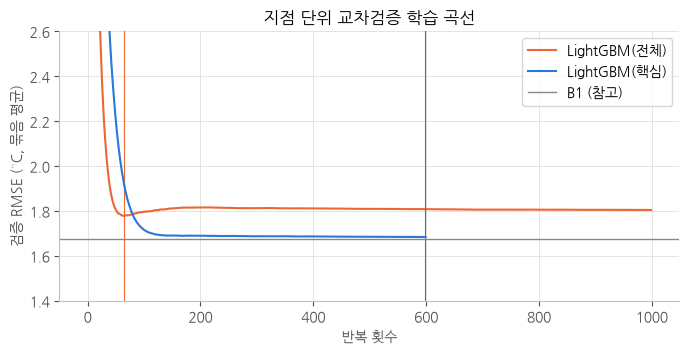

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, color in zip(LGB_PARAMS, ["#eb6834", "#2a78d6"]):
    curve = fold_models[name][1]
    ax.plot(curve, color=color, label=name)
    ax.axvline(best_iter[name], color=color, linewidth=0.8)
ax.axhline(np.sqrt((train_all["nbr_rst"] - train_all[TARGET]).pow(2).mean()), color="#898781",
           linewidth=1, label="B1 (참고)")
ax.set_xlabel("반복 횟수")
ax.set_ylabel("검증 RMSE (°C, 묶음 평균)")
ax.set_ylim(1.4, 2.6)
ax.set_title("지점 단위 교차검증 학습 곡선")
ax.legend()
plt.show()

변수 전체를 쓴 LightGBM은 몇십 번 반복 만에 검증 오차가 다시 커진다. 학습 지점의 고유한 특성(센서 위치, 포장, 주변 그늘 등)을
외워 버리고, 처음 보는 지점에는 일반화하지 못하는 것이다. 작은 트리와 핵심 변수만 쓴 모델은 이 문제가 덜하다.

In [8]:
def regression_scores(y_true, y_pred):
    """관측값 추정 성능 {"N", "BIAS", "MAE", "RMSE"}. BIAS = 평균(추정 - 관측)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = ~(np.isnan(y_true) | np.isnan(y_pred))
    err = y_pred[ok] - y_true[ok]
    return {"N": int(ok.sum()), "BIAS": err.mean(), "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())}


def score_table(df, preds):
    """지점별 성능 + 지점 평균 행."""
    rows = []
    for method in preds.columns:
        for stn, idx in df.groupby("stn").groups.items():
            rows.append({"stn": stn, "지점명": stations.loc[stn, "name"], "방법": method,
                         **regression_scores(df.loc[idx, TARGET], preds.loc[idx, method])})
    scores = pd.DataFrame(rows)
    mean = scores.groupby("방법", sort=False)[["N", "BIAS", "MAE", "RMSE"]].mean().reset_index()
    mean.insert(0, "지점명", f"{df['stn'].nunique()}개 지점 평균")
    mean.insert(0, "stn", "mean")
    return pd.concat([scores, mean], ignore_index=True)


cv_scores = score_table(train_all, oof)
cv_summary = cv_scores[cv_scores["stn"] == "mean"].set_index("방법")[["BIAS", "MAE", "RMSE"]]
cv_summary.sort_values("RMSE").round(3)

,BIAS,MAE,RMSE
방법,,,
앙상블,-0.014,1.144,1.597
Ridge(핵심),0.028,1.164,1.612
B1 주변 노면온도,-0.066,1.161,1.642
LightGBM(핵심),-0.005,1.194,1.649
LightGBM(전체),-0.052,1.287,1.754
B2 기온+노면편차,-0.058,1.319,1.824
B0 보간 기온,-1.995,2.398,3.120


In [9]:
MODEL_CANDIDATES = ["LightGBM(전체)", "LightGBM(핵심)", "Ridge(핵심)", "앙상블"]
FINAL = cv_summary.loc[MODEL_CANDIDATES, "RMSE"].idxmin()
print(f"최종 방법: {FINAL} (교차검증 RMSE {cv_summary.loc[FINAL, 'RMSE']:.3f}, "
      f"B1 {cv_summary.loc['B1 주변 노면온도', 'RMSE']:.3f})")

최종 방법: 앙상블 (교차검증 RMSE 1.597, B1 1.642)


지점별 교차검증 RMSE. 지점마다 편차가 크다. 서해안선 북부(군산휴·서김제·우곡3교)와 덕유산휴는 주변 관측소와 낮 시간 노면온도 차이가 커서
오차가 크다(약 1.9~2.5°C). 01-3의 4-2에서 본 것처럼 서김제는 낮 최고 노면온도가 다른 지점보다 크게 낮다.

In [10]:
cv_scores.pivot(index=["stn", "지점명"], columns="방법", values="RMSE")[list(oof.columns)].round(2)

,방법,B0 보간 기온,B1 주변 노면온도,B2 기온+노면편차,LightGBM(전체),LightGBM(핵심),Ridge(핵심),앙상블
stn,지점명,,,,,,,
12103,군산휴(도),2.90,2.16,2.16,2.08,1.94,1.85,1.95
12209,서김제(도),2.02,2.23,2.23,2.45,2.66,2.54,2.45
12210,부안고려청자휴(도),3.09,1.61,1.87,1.34,1.45,1.49,1.49
12211,고인돌휴(도),2.21,1.59,2.13,1.84,1.67,1.49,1.55
12409,우곡3교(도),1.99,2.08,2.08,2.01,2.15,2.09,2.07
23202,여산휴(도),3.86,1.28,1.88,1.83,1.36,1.39,1.31
23203,삼례졸음(도),3.18,1.62,1.68,1.56,1.46,1.53,1.51
23204,정읍휴(도),2.64,1.10,1.35,1.33,1.17,1.16,1.11
23403,호남터널(도),2.96,1.39,1.71,1.34,1.35,1.30,1.30


시간대와 대기 안정도에 따라 교차검증 오차가 어떻게 달라지는지 본다. 노면온도의 지점 간 차이는 낮에는 일사·그늘이,
밤에는 대기가 안정할수록 국지 지형이 만든다 (Chapman et al. 2001, 01-1의 0-3, 01-7의 13-5). 안정도는 지점별 보간 풍속·운량으로
Pasquill–Gifford 등급(D 바람·구름 많음 ~ G 고요)을 매긴다.

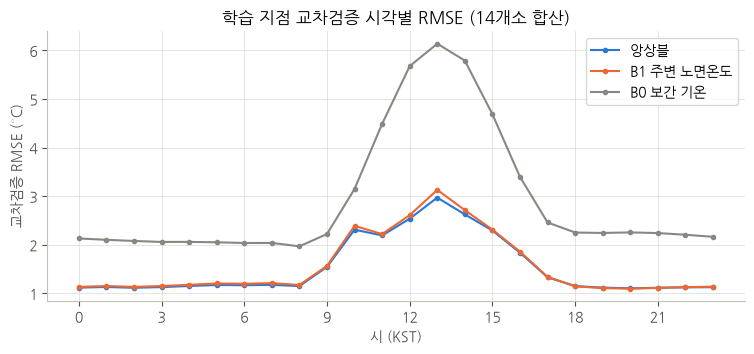

,밤 시간 비율,앙상블,B1 주변 노면온도,B0 보간 기온
D,0.080,0.956,0.991,1.947
E,0.138,1.113,1.130,2.146
F,0.071,1.222,1.218,2.281
G,0.712,1.143,1.156,2.141


In [11]:
def rmse(e):
    return np.sqrt((e ** 2).mean())


err = pd.DataFrame({name: oof[name] - train_all[TARGET] for name in [FINAL, "B1 주변 노면온도", "B0 보간 기온"]})
hour = train_all["time"].dt.hour
ws, octa = train_all["ws"], train_all["cloud"] * 0.8
stability = pd.Series(np.select([ws > 5, (ws >= 3) & (octa >= 4), ws >= 3, (ws >= 2) & (octa >= 4), ws >= 2, ws < 2],
                                ["D", "D", "E", "E", "F", "G"], "?"), index=train_all.index)
night = ((hour >= 19) | (hour <= 6)) & (stability != "?")
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, color in zip(err.columns, ["#2a78d6", "#eb6834", "#898781"]):
    ax.plot(range(24), err.groupby(hour)[name].agg(rmse), marker="o", markersize=3, color=color, label=name)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("교차검증 RMSE (°C)")
ax.set_title("학습 지점 교차검증 시각별 RMSE (14개소 합산)")
ax.legend()
plt.show()
by_class = err[night].groupby(stability[night]).agg(rmse)
by_class.insert(0, "밤 시간 비율", stability[night].value_counts(normalize=True))
by_class.round(3)

- **B0(노면온도 = 보간 기온)는 RMSE 3.1°C, BIAS -2.0°C**로 가장 나쁘다. 낮에는 일사로 노면이 기온보다 훨씬 따뜻해(13시 RMSE 6°C 이상)
  기온만으로는 노면온도를 설명할 수 없다. 에너지 수지의 일사·복사 항을 반영하는 주변 노면온도(B1)와 모델이 필요한 이유이다.
- 모델 오차도 한낮(13시 약 3°C)에 가장 크고 밤에는 1.1°C 안팎이다.
- 밤 오차는 바람·구름이 많은 D 등급에서 가장 작고(0.96°C), 안정한 F·G 등급에서 커진다(1.14~1.22°C).
  대기가 안정할수록 지점마다 국지 요인(교량, 그늘, 냉기호)이 커진다는 Chapman et al.(2001)의 결론과 맞다.
  결빙이 주로 생기는 밤 가운데 맑고 고요한 밤의 추정이 더 불확실하다는 점을 05-1의 위험도 해석에서 고려한다.

## 저장

- `data/processed/estimation_oof.parquet`: 학습 지점 교차검증 예측 (2절 후보 7개) → 03-2·03-3에서 사용
- `data/processed/estimation_cv.json`: 핵심 변수, LightGBM 설정·최적 반복 횟수, 교차검증 묶음, 앙상블 구성, 최종 방법
- `data/results/estimation_cv_scores.csv`: 학습 지점 교차검증 성능 (지점별 + 지점 평균)

In [12]:
BASE_METHODS = list(oof.columns)  # 2절 후보 (03-3의 검증 지점 표에 쓴다)
oof.assign(stn=train_all["stn"], time=train_all["time"]).to_parquet(
    config.PROCESSED_DIR / "estimation_oof.parquet", index=False)
cv_info = {"target": TARGET, "core": CORE, "lgb_params": LGB_PARAMS, "best_iter": best_iter,
           "folds": [[int(s) for s in v] for v in folds], "ensemble": ENSEMBLE, "final": FINAL,
           "base_methods": BASE_METHODS}
with open(config.PROCESSED_DIR / "estimation_cv.json", "w", encoding="utf-8") as f:
    json.dump(cv_info, f, ensure_ascii=False, indent=2)
cv_scores.round(4).to_csv(config.RESULT_DIR / "estimation_cv_scores.csv", index=False, encoding="utf-8-sig")
print("저장 완료")

저장 완료
